In [1]:
import time
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
#from Minimal_Model_2D import *
import Minimal_Model_2D as mm2d
import time

np.set_printoptions(threshold=sys.maxsize)

In [2]:
NSM = 60            # number of sm x lattice points
M = 60              # should be atleast thrice confinement length
AX = 5              # lattice spacing in nm
AY = 5              # lattice spacing in nm
DELTA = 0.165       # in meV
MEFF_SC = 0.023     # proximitized Ge
MEFF_SM = 0.023     # Ge
NSC = 800
NTOT = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT = 400        # meV-nm^3 # 20 is within perturbative regime for widths atleast up to 100 nm
K_NUM = 8           # No of eigenvalues needed to be found 
#W_MIN = 50

LY = 75           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

print('lengths=', M*AY, LY)
OMEGA = 2*4*hbm/LY**2/MEFF_SC

print('subband energies=', OMEGA/2, 3*OMEGA/2)

print('4t=', 4*hbm/AX**2/MEFF_SM)

MU_SM = 0.8 + OMEGA/2
MU_SC = 0.8 + OMEGA/2

print('mu = ', MU_SM)


ModCT = mm2d.twoD_Minimal_Model(NTOT, NSM, NSC, M, AX, AY, OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)

lengths= 300 75
subband energies= 1.1789724682017417 3.536917404605225
4t= 265.2688053453919
mu =  1.9789724682017418


In [4]:
#XCT = np.linspace((NSC-10)*AX, (NSC+NSM+10)*AX, 35)
#XCT = np.linspace(0, (NTOT)*AX, 35)
XCT = (NSC+NSM/2)*AX
YCT = np.linspace(-200*AY,(M+200)*AY,101)

print('X co-ordinate of charge trap =', XCT )

ZCT = 50
ZIM = 64
Ep = np.empty((YCT.shape[0],K_NUM))

for i in range(YCT.shape[0]):

    H = ModCT.H_sys(PHI, 'cu', XCT, YCT[i], ZCT, ZIM)

    E = eigsh(H, k=K_NUM, sigma=0, return_eigenvectors=False )

    Es = np.sort(E)

    Ep[i,:] = Es

    if i %10 ==0 :
        print(Ep[i,:])

np.save('cubic_E_vs_yct_Zdiff_{}_wider_yct.npy'.format(ZIM-ZCT), Ep)

X co-ordinate of charge trap = 4150.0


KeyboardInterrupt: 

In [32]:
#XCT = np.linspace((NSC-10)*AX, (NSC+NSM+10)*AX, 21)
#YCT = M/2*AY
#Ep = np.load("C:\\Users\\Vivrekar\\Desktop\\Spin_Splitting_Ge_ABS\\disorder_charge_trap\\cubic_E_vs_yct_Zdiff_0.20000000000000284.npy")

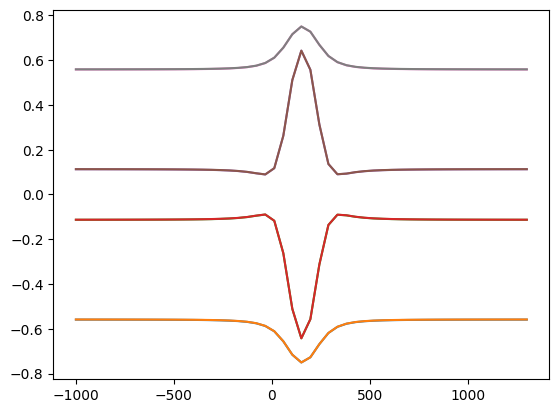

In [5]:
plt.plot(YCT, Ep[:, :])
#plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
#plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')

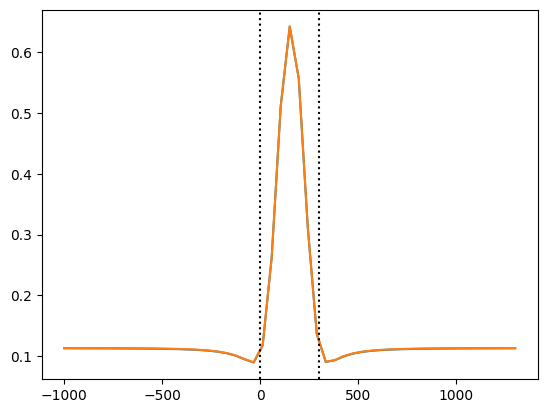

In [9]:
plt.plot(YCT, Ep[:, K_NUM//2:K_NUM//2+2])
plt.axvline(x=0, color='black', linestyle='dotted')
plt.axvline(x=M*AY, color='black', linestyle='dotted')

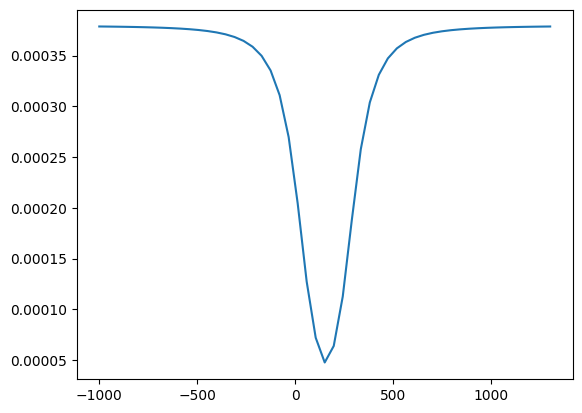

In [7]:
plt.plot(YCT, (Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2])/DELTA)
#plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
#plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')
#plt.ylim(ymin=0,ymax = 1.2*np.max(Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2]))

(0.0, 0.0003952182697113879)

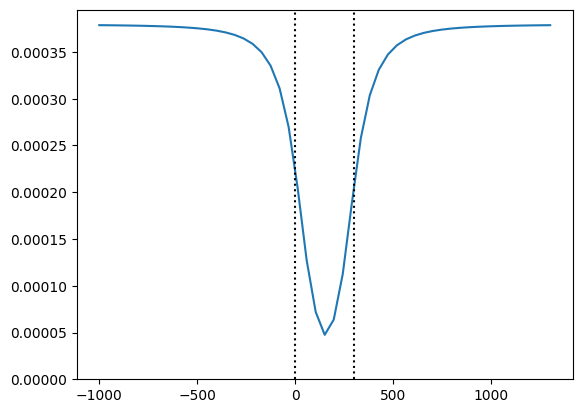

In [10]:
plt.plot(YCT, Ep[:, (K_NUM//2+1]-Ep[:, K_NUM//2])/DELTA)
#plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
#plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')

plt.axvline(x=0, color='black', linestyle='dotted')
plt.axvline(x=M*AY, color='black', linestyle='dotted')
plt.ylim(ymin=0)

In [9]:
print(XCT)

4150.0


In [9]:
cubic_spin_split = Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2] 

min_spin_split = np.min(cubic_spin_split)

max_spin_split = np.max(cubic_spin_split)



In [10]:
print(max_spin_split-min_spin_split)

0.00014755373977248798


In [11]:
percent_spin_split = (max_spin_split-min_spin_split)/max_spin_split

In [12]:
print(percent_spin_split)

0.9347044126909262


(0.0, 0.00018943367049828463)

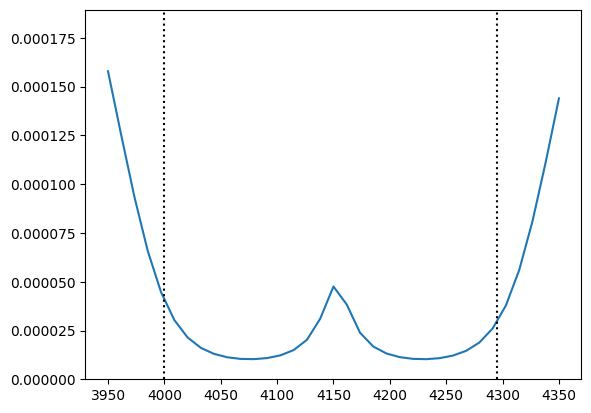

In [7]:
plt.plot(XCT, Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2])
plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')
plt.ylim(ymin=0,ymax = 1.2*np.max(Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2]))

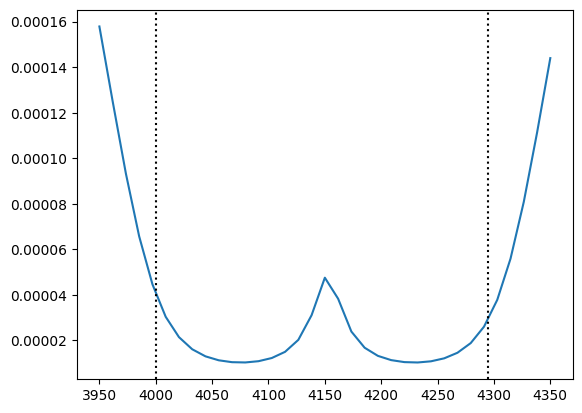

In [8]:
plt.plot(XCT, Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2])
plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')
#plt.ylim(ymin=0,ymax = 1.2*np.max(Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2]))

In [19]:
XCT = np.linspace((NSC-10)*AX, (NSC+NSM+10)*AX, 21)
YCT = M/2*AY
Ep = np.load("C:\\Users\\Vivrekar\\Desktop\\Spin_Splitting_Ge_ABS\\disorder_charge_trap\\cubic_E_vs_xct_V1.npy")

(0.0, 0.00014110027318041672)

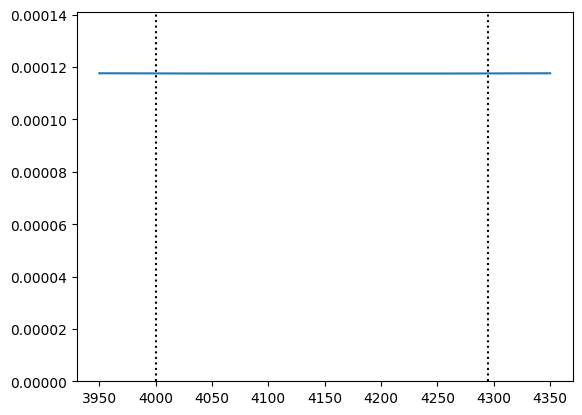

In [20]:
plt.plot(XCT, Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2])
plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')
plt.ylim(ymin=0,ymax = 1.2*np.max(Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2]))

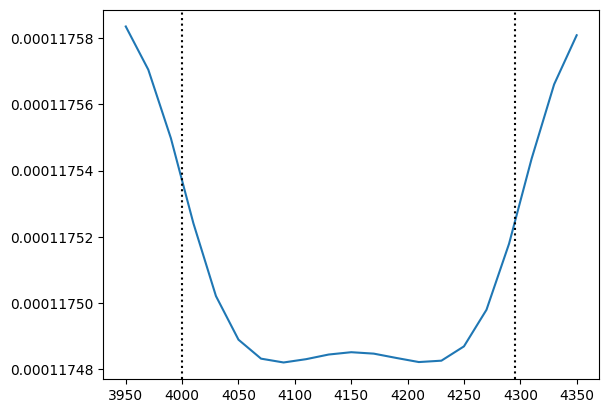

In [21]:
plt.plot(XCT, Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2])
plt.axvline(x=NSC*AX, color='black', linestyle='dotted')
plt.axvline(x=(NSC+NSM-1)*AX, color='black', linestyle='dotted')
#plt.ylim(ymin=0,ymax = 1.2*np.max(Ep[:, K_NUM//2+1]-Ep[:, K_NUM//2]))